## Digital towers (LDraw)
Valid random stacks on a 16 x 16 stud grid, built from our 45 pieces. Each tower is rendered from random angles with an exact per-brick id mask (so exact boxes, visible parts only) and exported as an `.ldr` file. The `.ldr` is also the format the final recognizer should output.
First check by eye: is the camera above the tower (not below)? Do the boxes sit on the bricks? Does the `.ldr` open in LDView / Studio and look like the picture?

**What this notebook does.** Builds random but physically valid towers from the set's pieces, renders them from random camera angles with an exact per-brick mask, and exports each one as an `.ldr` file (the LDraw format the final recognizer should output). It then measures how well the current lookup names bricks cut out of these renders (the sim-to-real gap).

**Needs:** `ldraw/`, `data/element_map.csv`, `data/lego_colors.csv`, `labeling/tower_classes.txt`, `data/gallery.npz`. **Writes:** `output/tower_*.ldr`, `output/digital_towers.png`, `output/tower_*_labels.json`.

Load the list of pieces that exist in the LDraw library.

In [1]:
import os
if os.path.basename(os.getcwd()) == 'notebooks': os.chdir('..')   # all paths below are from the repo root
import csv, sys, numpy as np, matplotlib.pyplot as plt
sys.path.insert(0, '.'); import ldraw_render as R

ld = {r['bricklink_name']: int(r['ldraw_code']) for r in csv.DictReader(open('data/lego_colors.csv'))}   # element_map.csv uses the BrickLink color names
PARTS = []   # the 45 pieces as (LDraw part, LDraw color); a part the LDraw library lacks is skipped
for r in csv.DictReader(open('data/element_map.csv')):
    try: R.flatten(r['part_num'] + '.dat'); PARTS.append((r['part_num'], ld[r['color']]))
    except (FileNotFoundError, KeyError) as e: print('skipped', r['part_num'], r['color'], '-', repr(e))
print(len(PARTS), 'pieces')

skipped 6178pr0002 Light Bluish Gray - FileNotFoundError('LDraw file not found: 6178pr0002.dat')
44 pieces


**Result:** 44 pieces. 6178pr0002 is missing from LDraw.

Build and render 8 random towers, draw a box around every visible brick, and save each tower as an `.ldr` file.

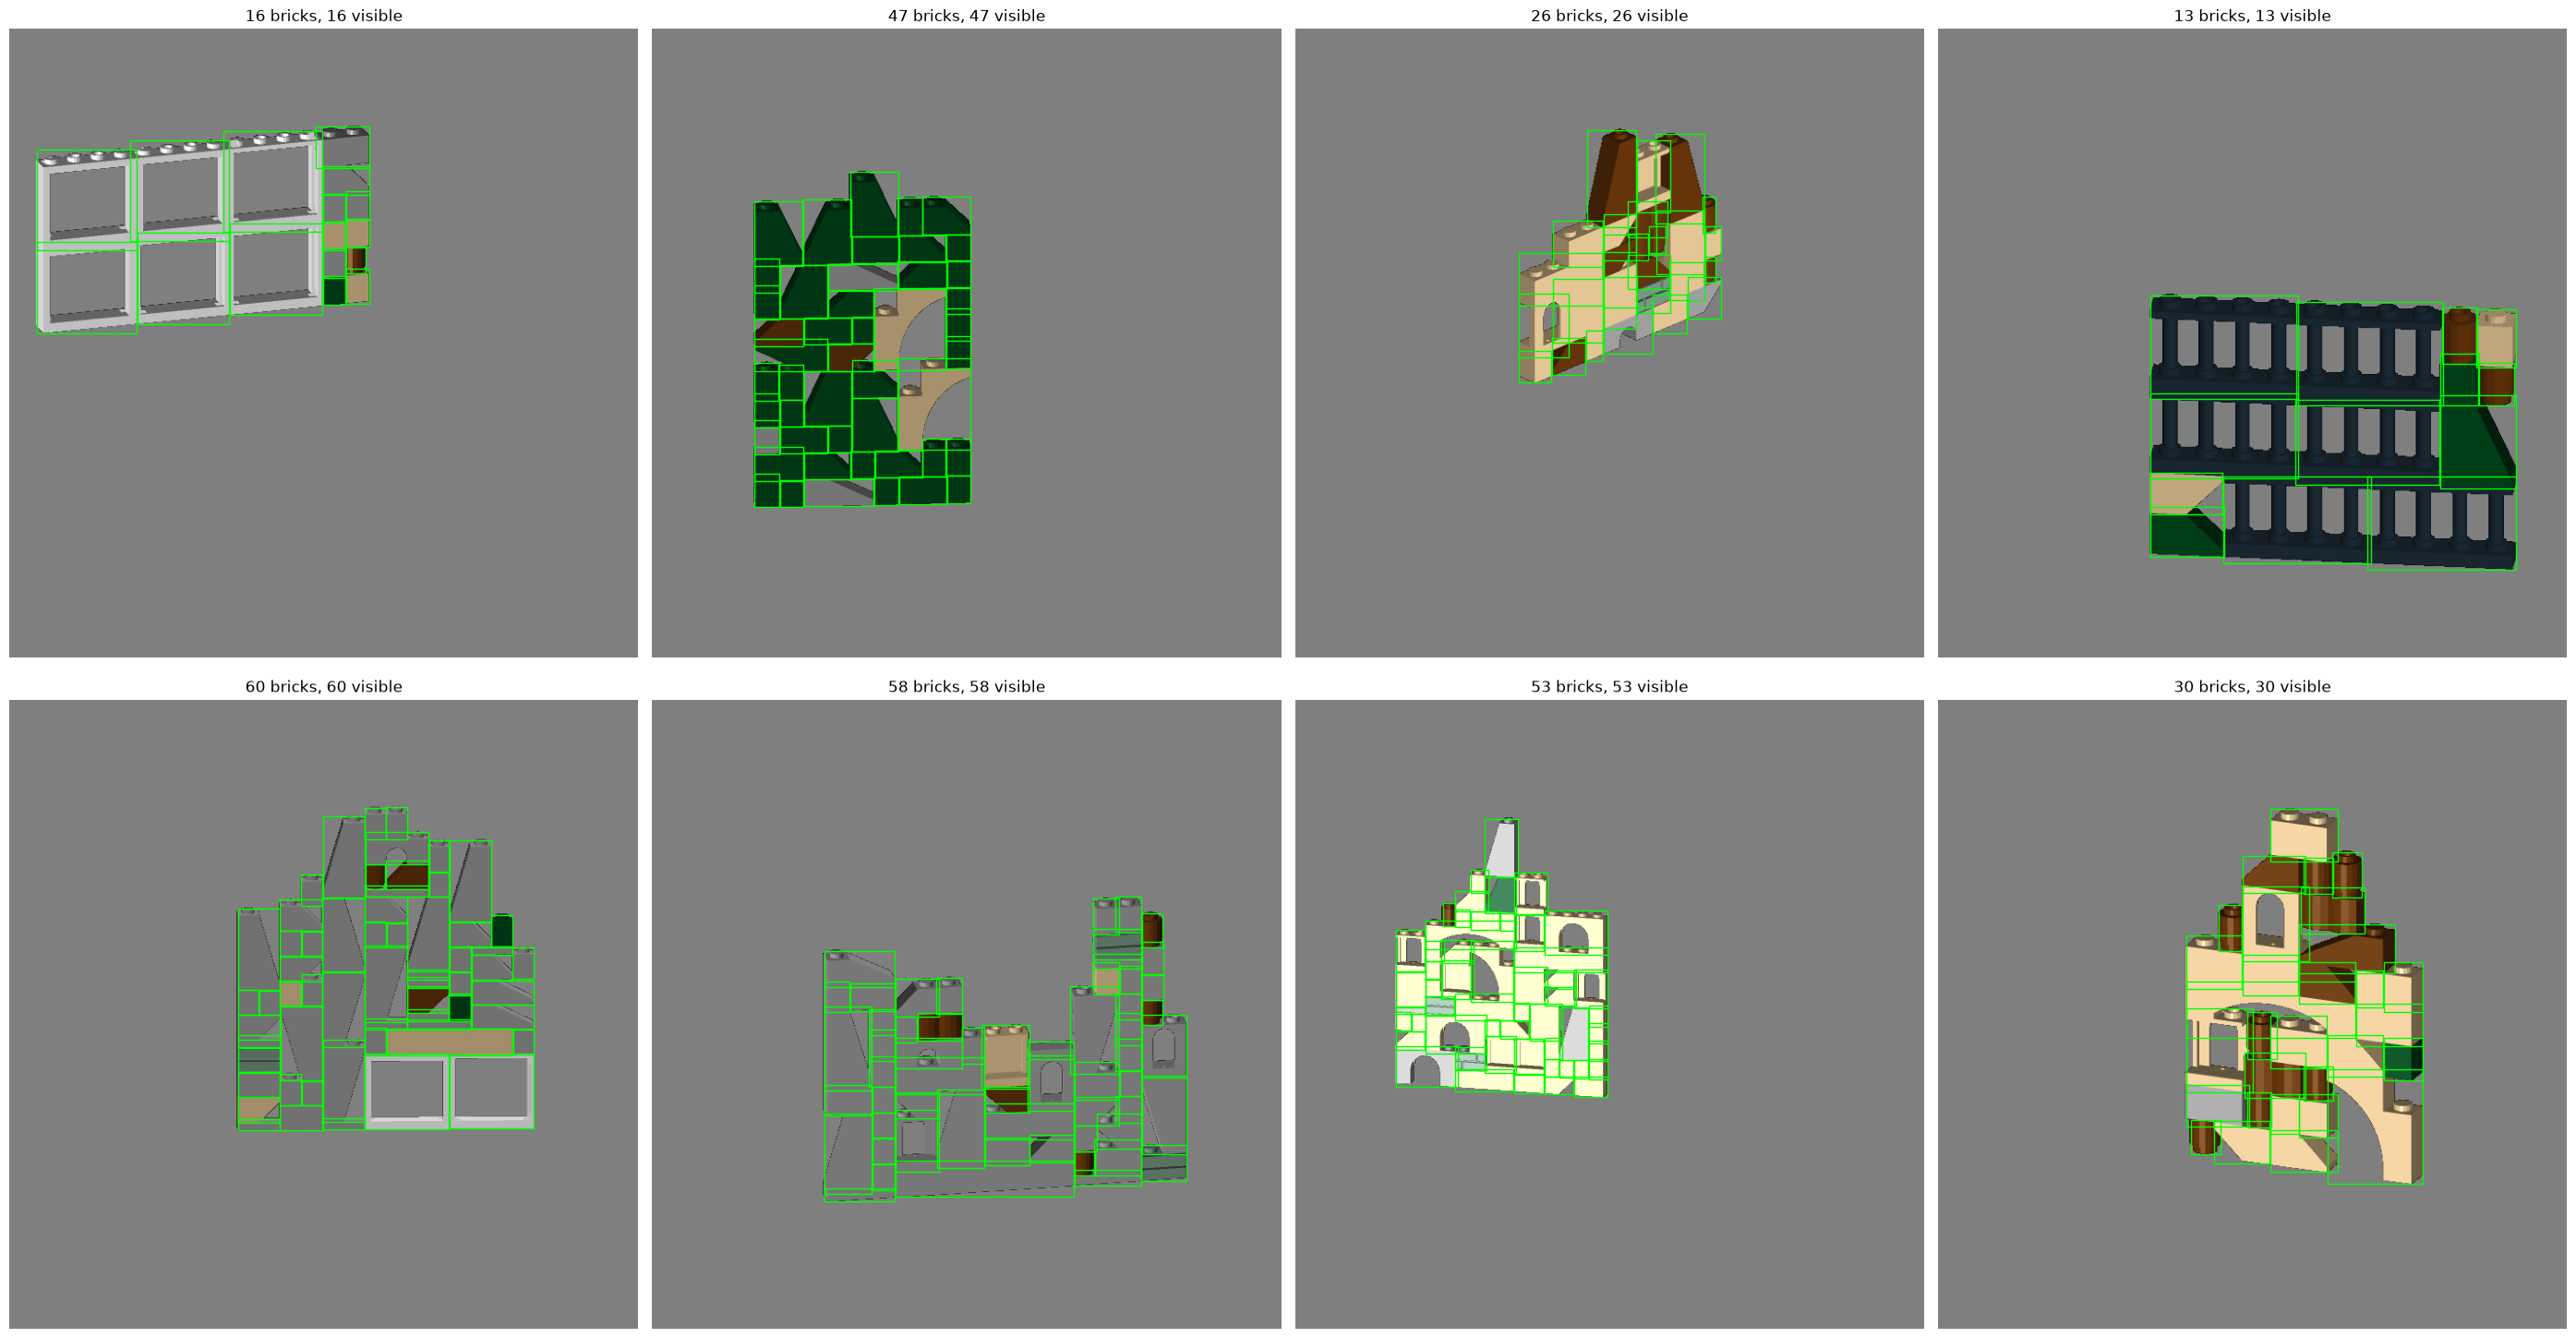

In [2]:
# 8 random towers (random width, height profile, colors, camera, zoom, position in the frame) with exact boxes from the id mask.
# Also writes output/tower_<k>.ldr and output/digital_towers.png. RENDERS keeps (tower, picture, ids) for the labels cell below.
os.makedirs('output', exist_ok=True)
rng = np.random.default_rng(3); RENDERS = []
fig, ax = plt.subplots(2, 4, figsize=(28, 15))
for k, a in enumerate(ax.flat):
    tower = R.make_tower(PARTS, rng); R.to_ldr(tower, f'output/tower_{k}.ldr')
    rgba, ids = R.render_scene(tower, size=700, rng=rng); RENDERS.append((tower, rgba, ids))
    a.imshow(np.where(rgba[..., 3:] > 0, rgba[..., :3], 127)); a.axis('off')
    for b in np.unique(ids)[1:]:
        ys, xs = np.where(ids == b)
        a.add_patch(plt.Rectangle((xs.min(), ys.min()), xs.max() - xs.min(), ys.max() - ys.min(), fill=False, color='lime', lw=1))
    a.set_title(f'{len(tower)} bricks, {len(np.unique(ids)) - 1} visible')
plt.tight_layout(); fig.savefig('output/digital_towers.png', dpi=60, bbox_inches='tight'); plt.show()

**Result:** Check by eye: the camera should be above the tower and the boxes should sit on the bricks. Open an `.ldr` in LDView or Studio to compare it with the picture.

Label every visible brick and run three cross-checks: no floating bricks, no boxes outside the picture, and colors that match the palette.

tower 0: 16 bricks, 16 labeled (visible) | floating bricks: 0 | boxes outside the picture: 0 | colour looks wrong (cosine < 0.9): 0 []


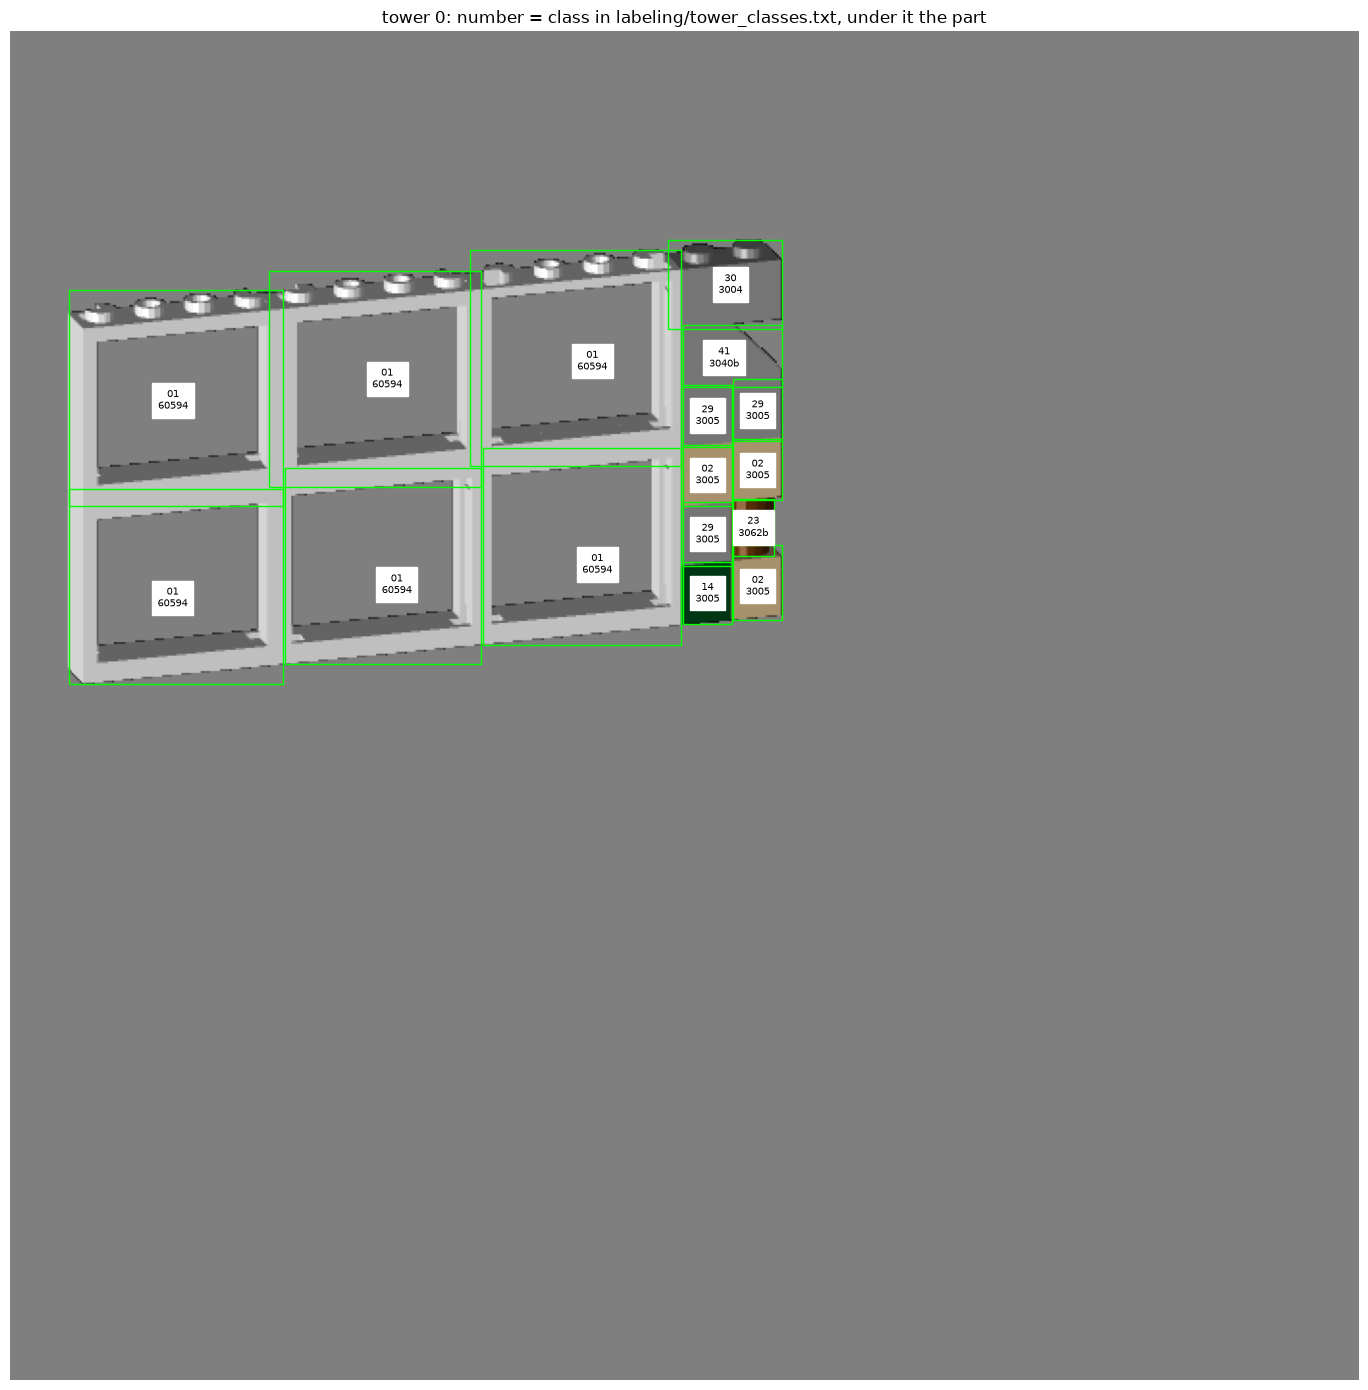

tower 1: 47 bricks, 47 labeled (visible) | floating bricks: 0 | boxes outside the picture: 0 | colour looks wrong (cosine < 0.9): 0 []


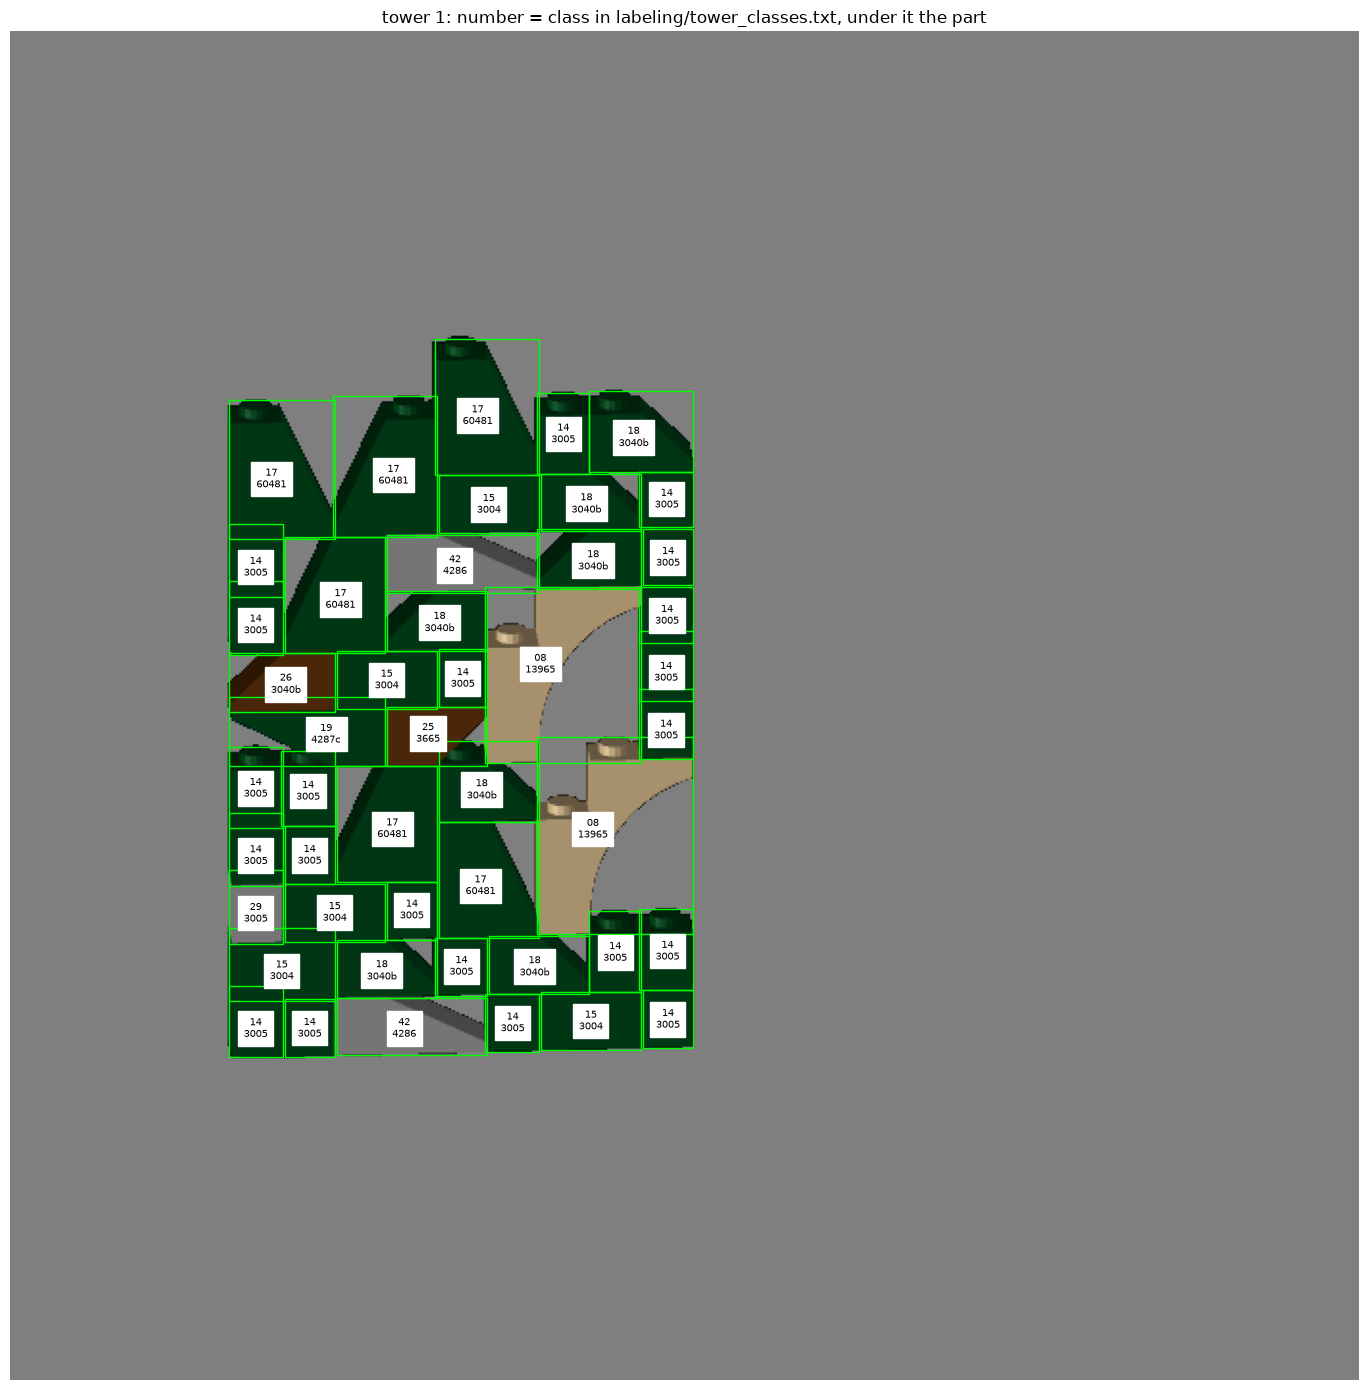

tower 2: 26 bricks, 26 labeled (visible) | floating bricks: 0 | boxes outside the picture: 0 | colour looks wrong (cosine < 0.9): 0 []


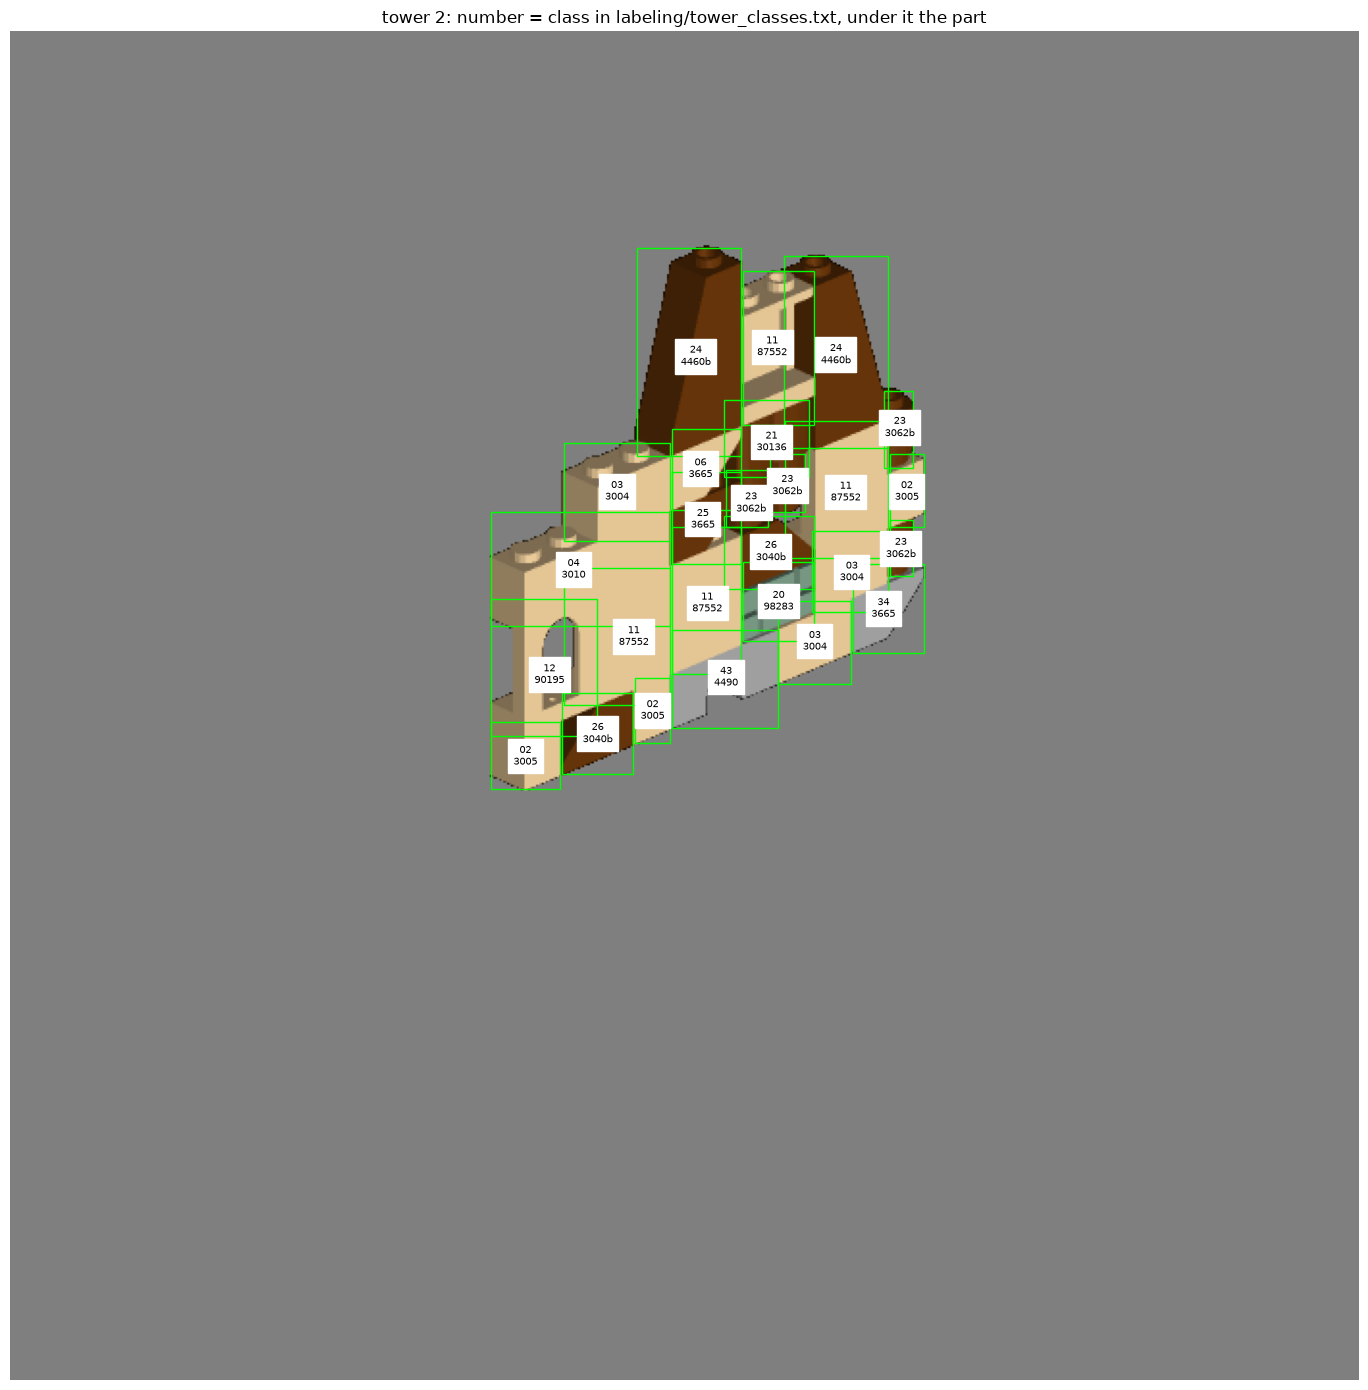

tower 3: 13 bricks, 13 labeled (visible) | floating bricks: 0 | boxes outside the picture: 0 | colour looks wrong (cosine < 0.9): 0 []


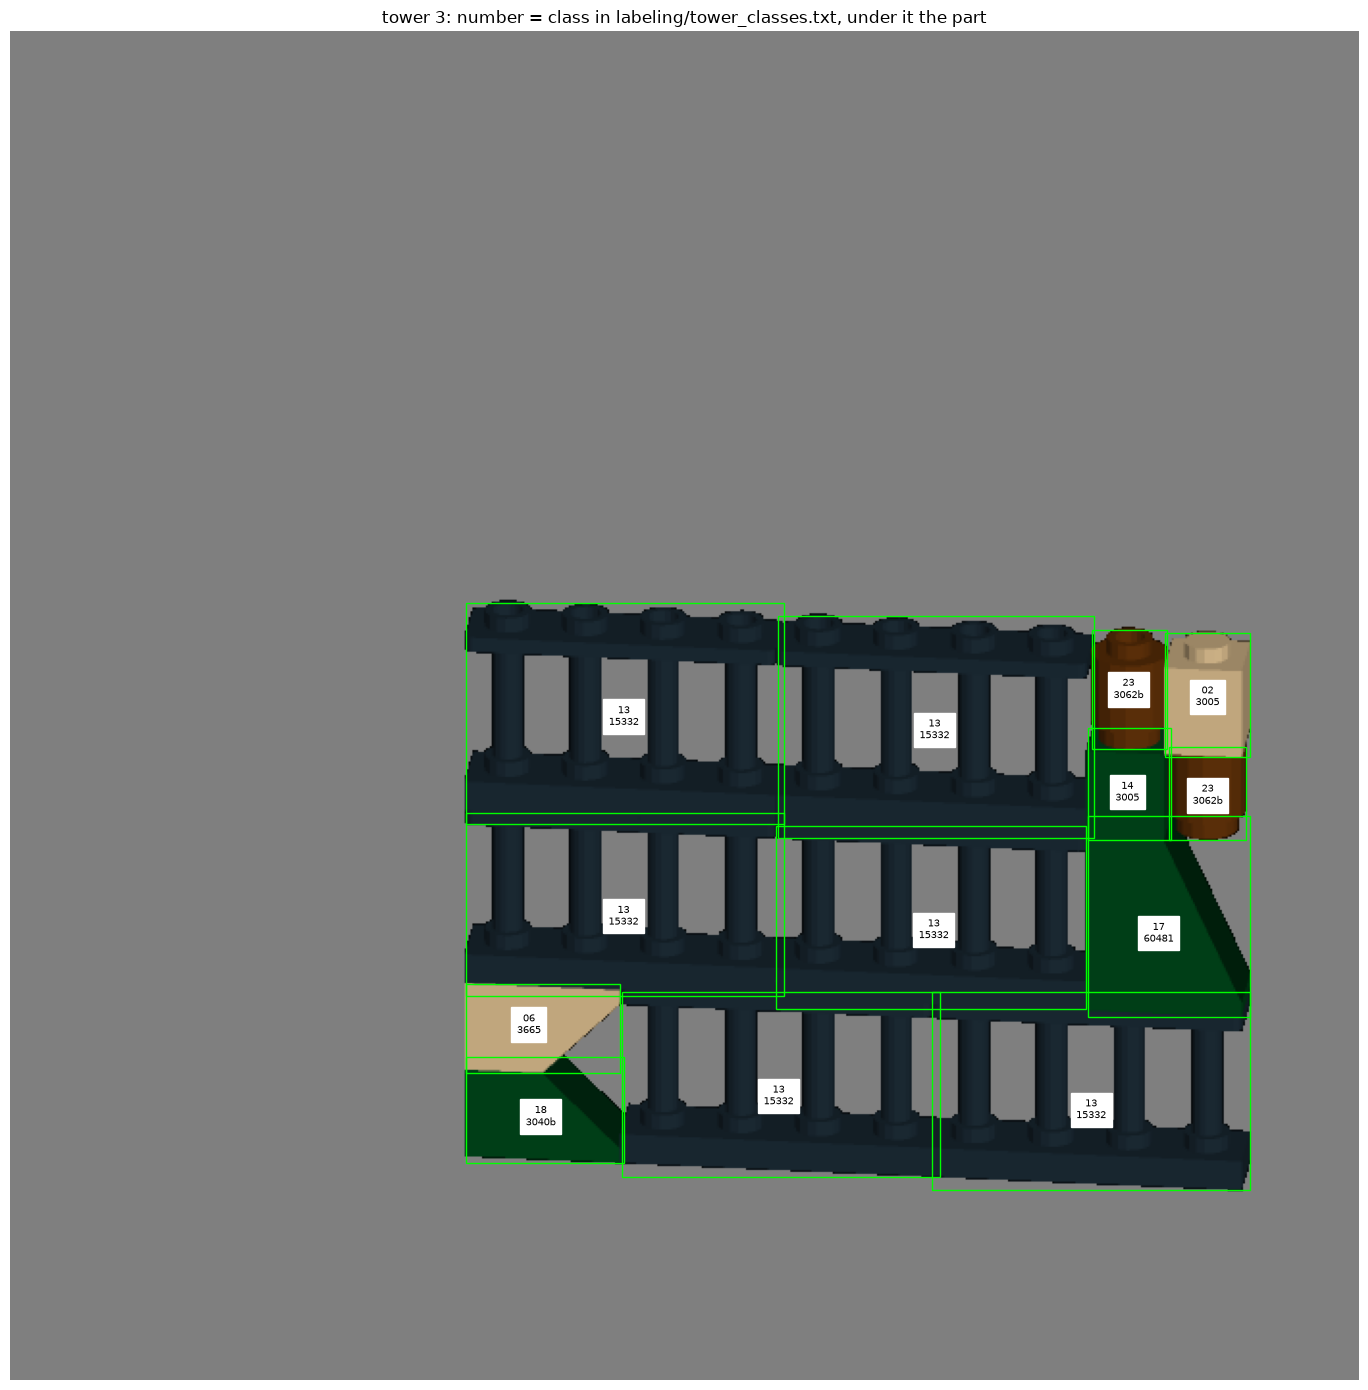

tower 4: 60 bricks, 60 labeled (visible) | floating bricks: 0 | boxes outside the picture: 0 | colour looks wrong (cosine < 0.9): 0 []


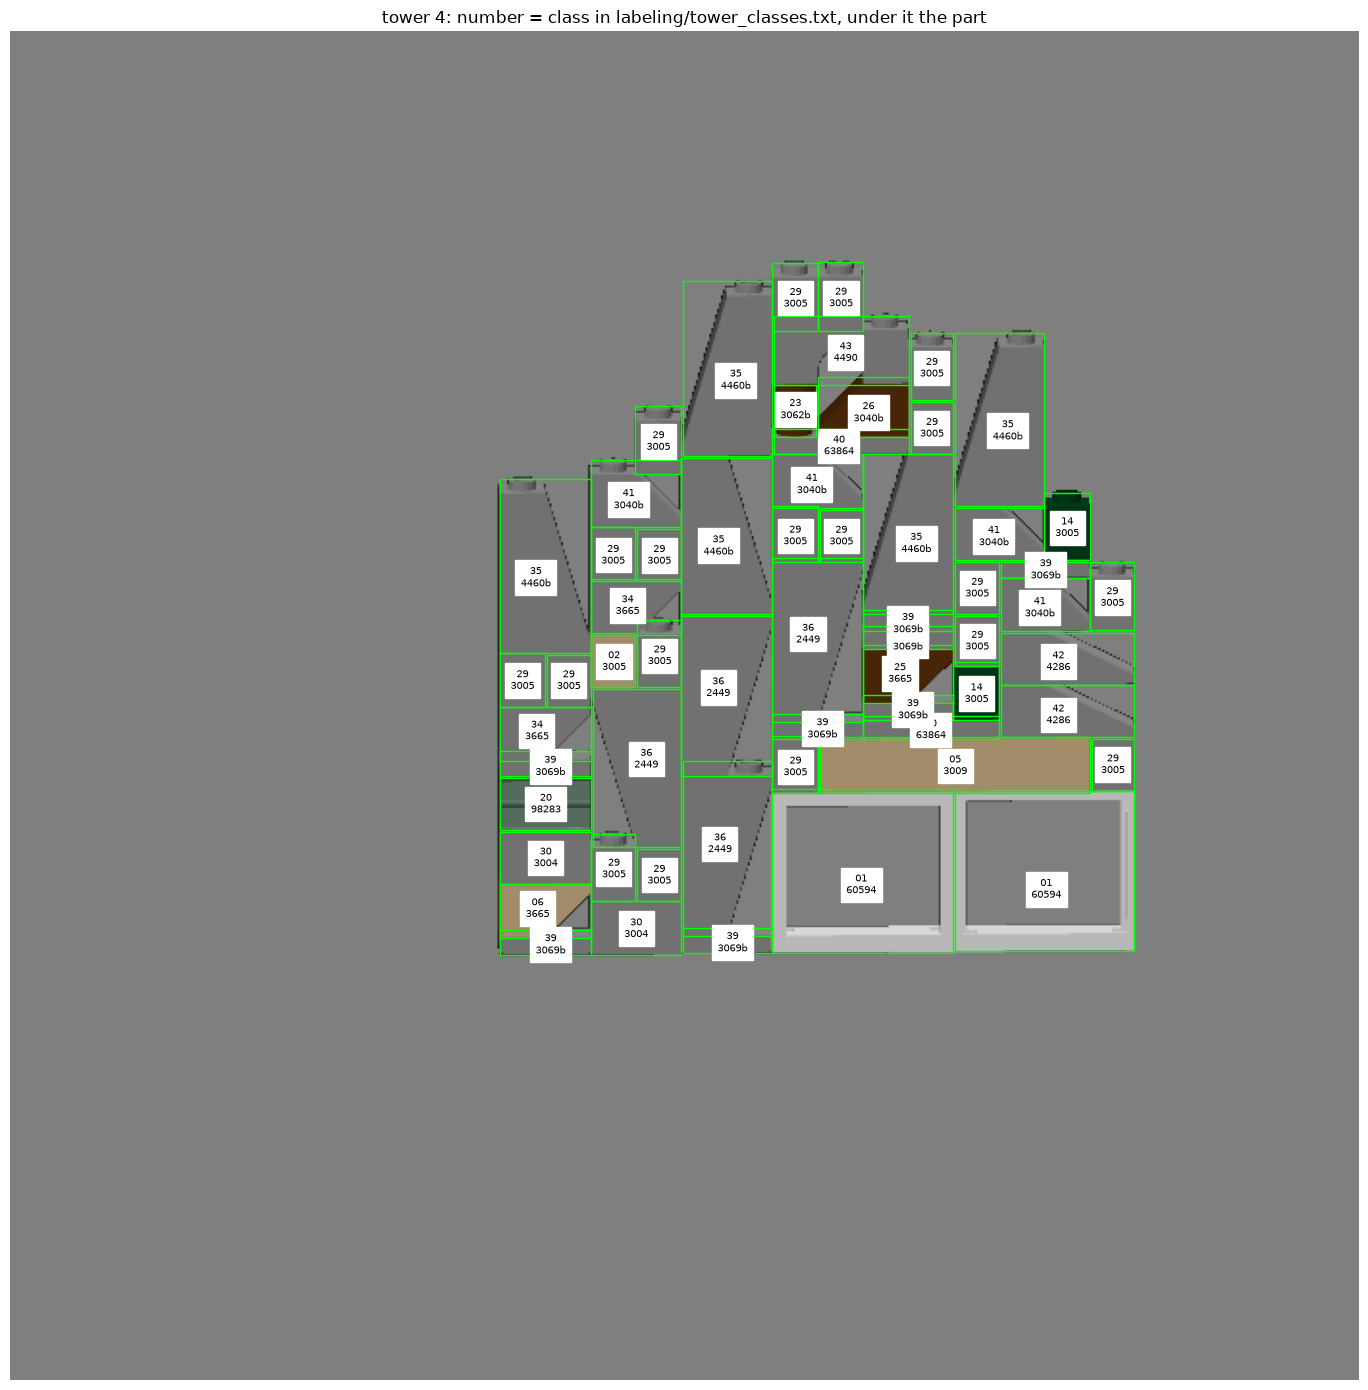

tower 5: 58 bricks, 58 labeled (visible) | floating bricks: 0 | boxes outside the picture: 0 | colour looks wrong (cosine < 0.9): 0 []


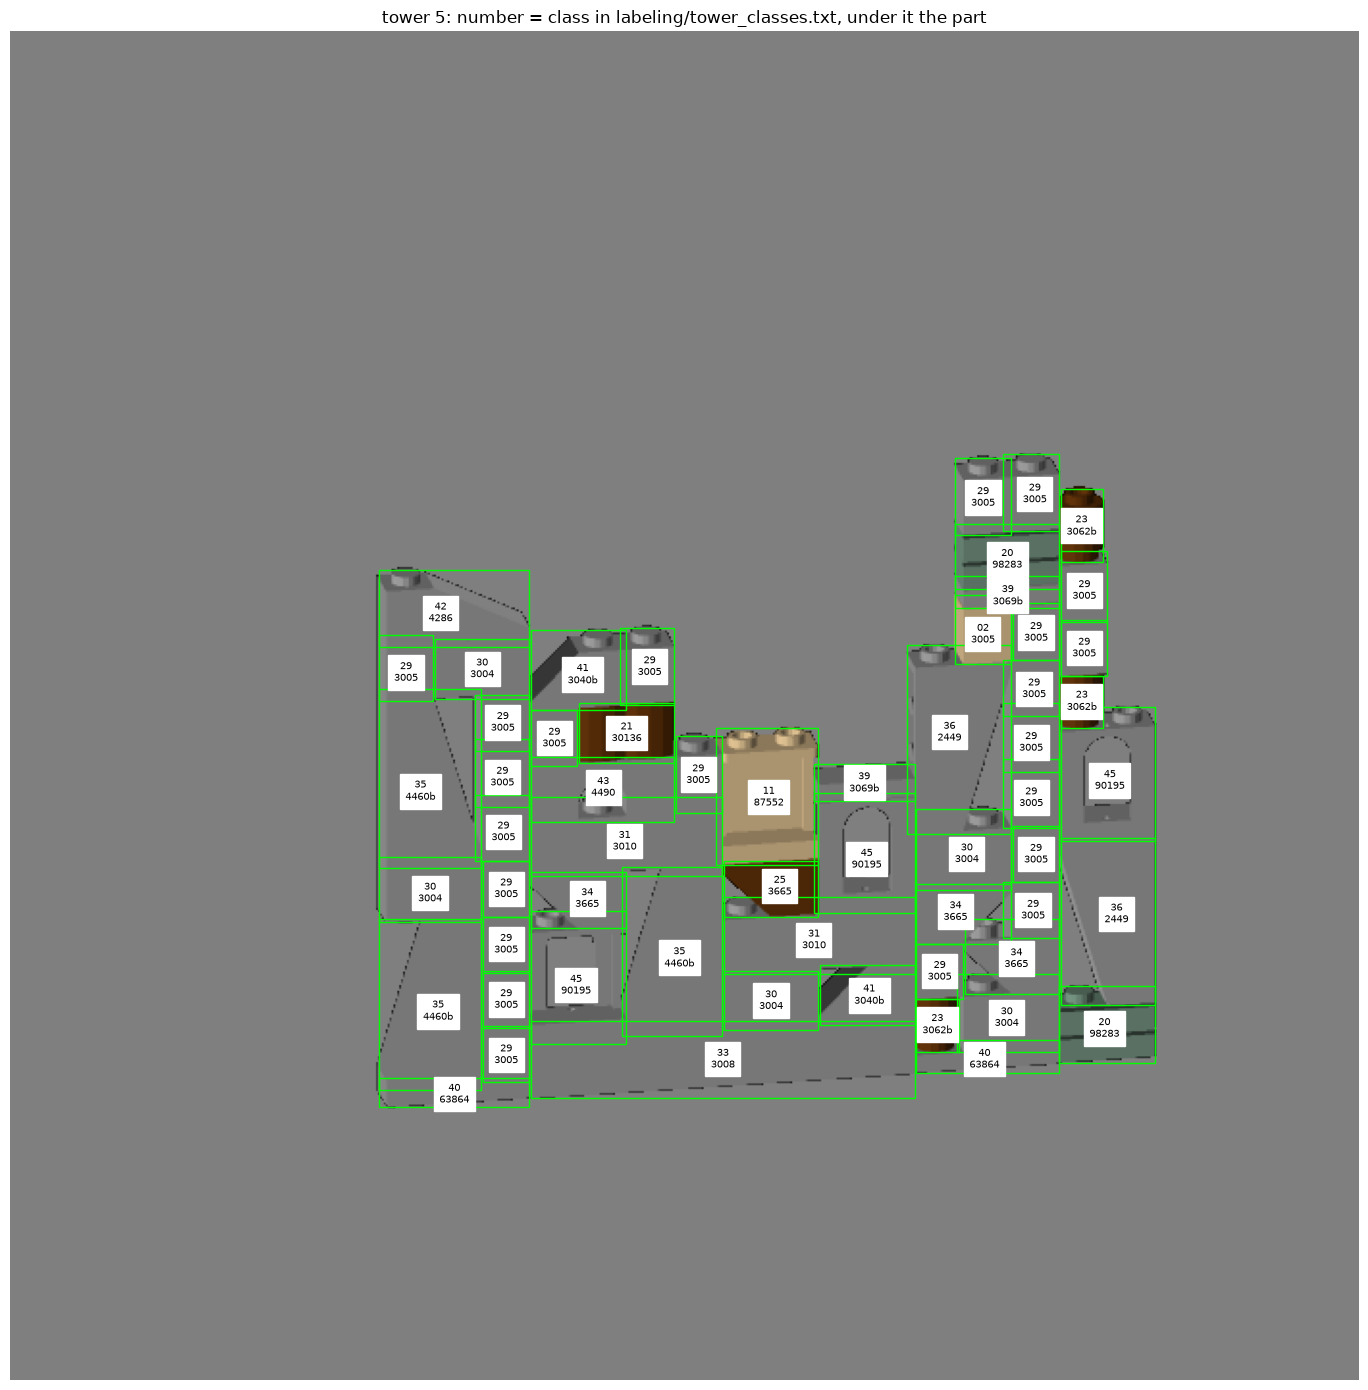

tower 6: 53 bricks, 53 labeled (visible) | floating bricks: 0 | boxes outside the picture: 0 | colour looks wrong (cosine < 0.9): 1 [('17_60481_Dark_Green', 0.899)]


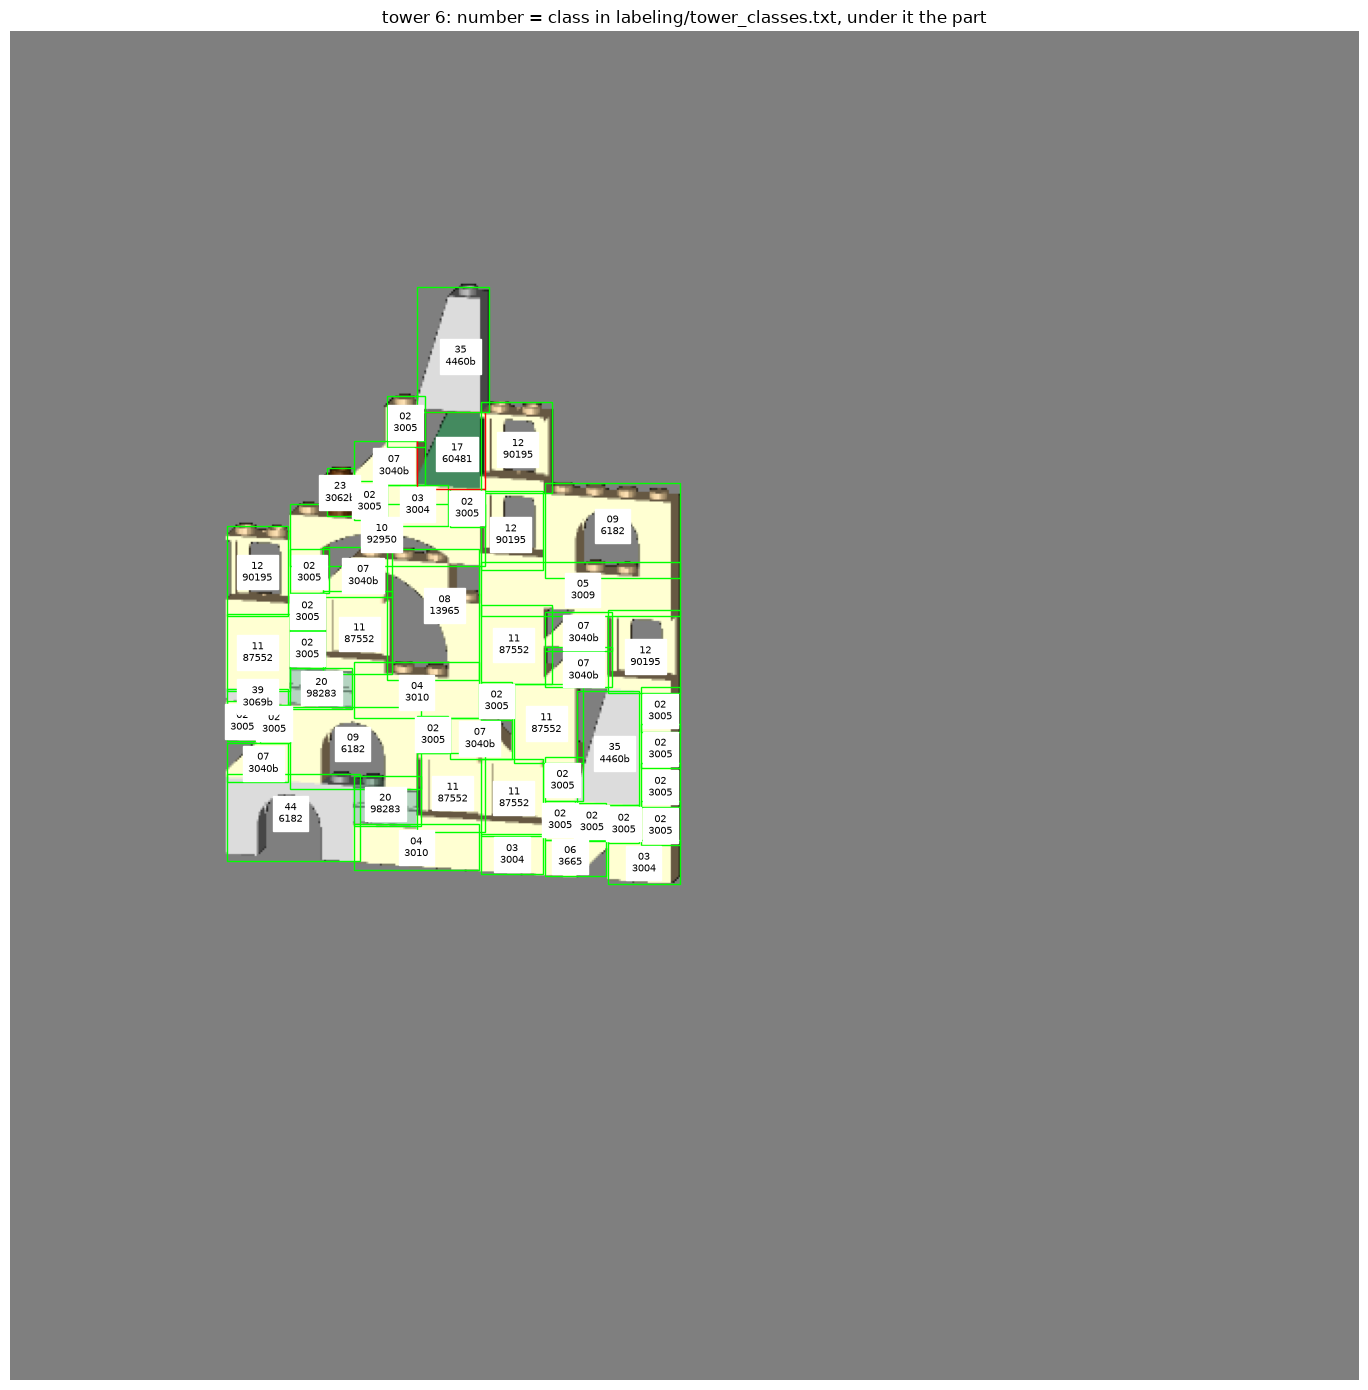

tower 7: 30 bricks, 30 labeled (visible) | floating bricks: 0 | boxes outside the picture: 0 | colour looks wrong (cosine < 0.9): 0 []


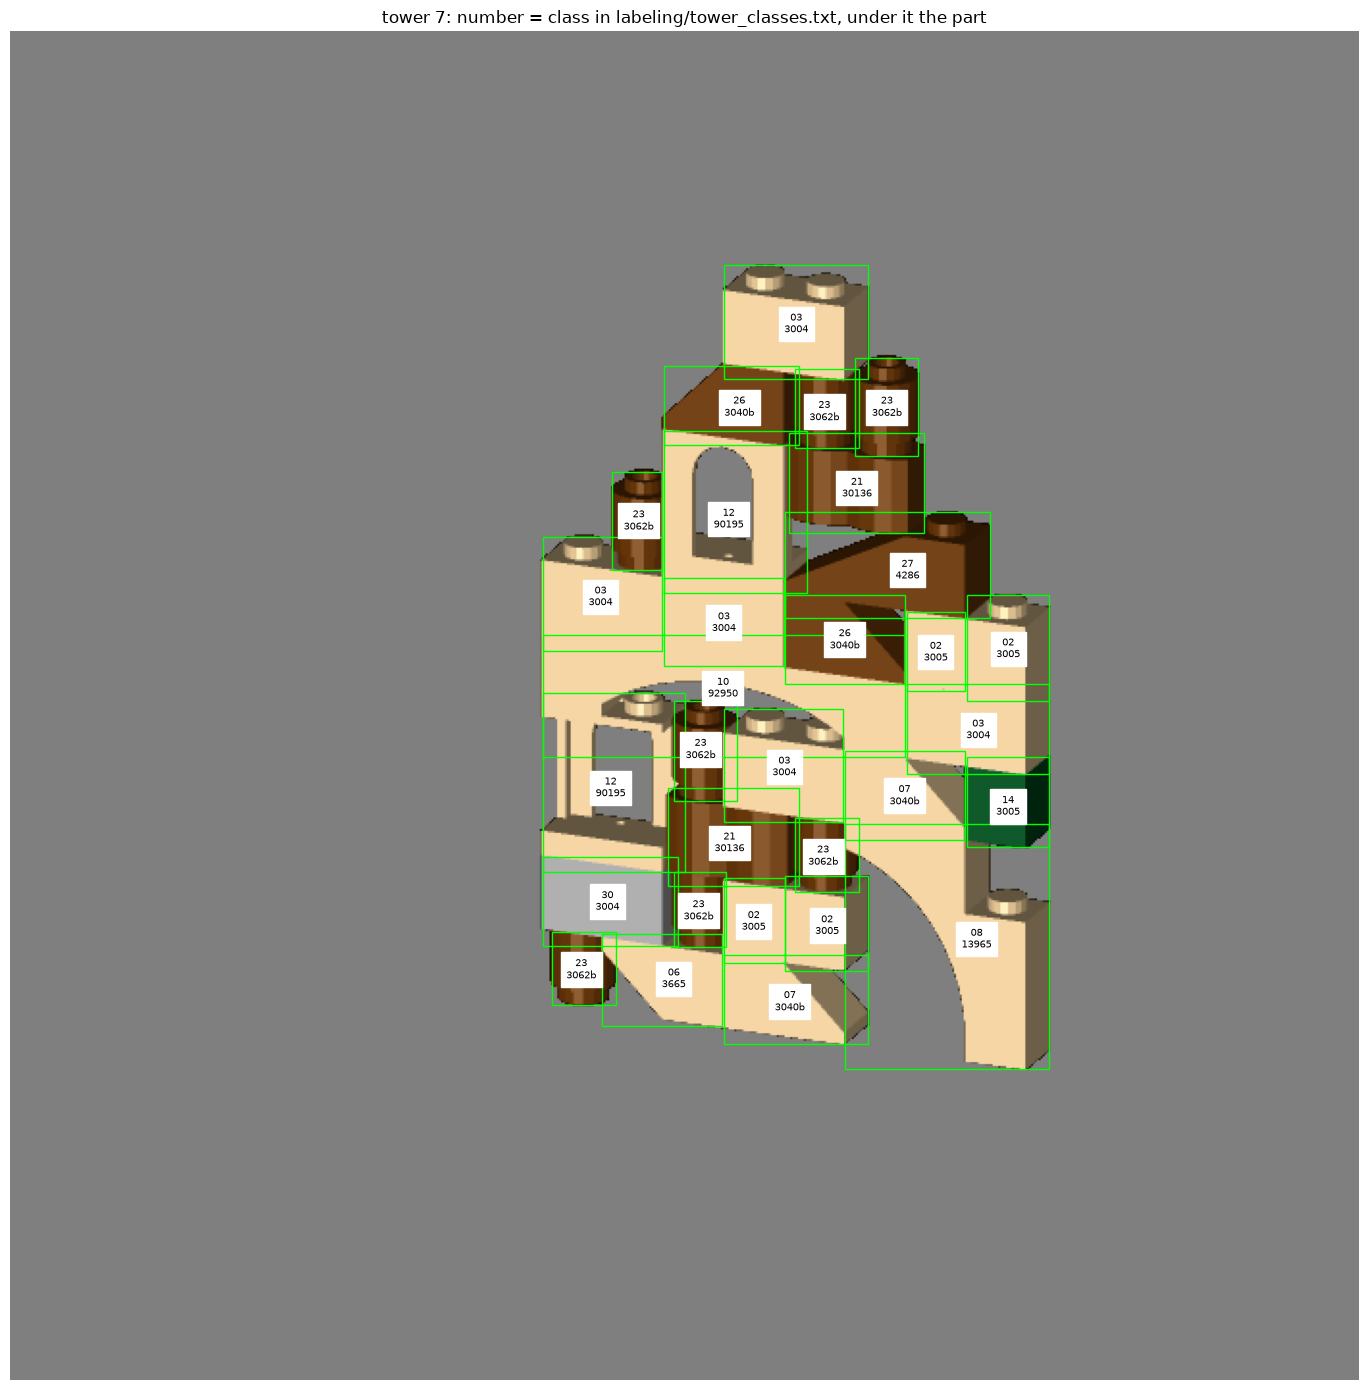

In [3]:
# LABELS + CROSS-CHECKS for the towers above. Class = line of labeling/tower_classes.txt (same numbers as the labeler and brick_sheet.png).
# One label per VISIBLE brick (hidden bricks get none). Labels go to output/tower_<k>_labels.json, the labeled picture to output/tower_<k>_labeled.png.
import json
classes = open('labeling/tower_classes.txt').read().split()
cls = {(r['part_num'], ld[r['color']]): classes[i] for i, r in enumerate(csv.DictReader(open('data/element_map.csv')))}   # (LDraw part, LDraw color) -> '27_4286_Reddish_Brown'
pal = R.colors()

def supported(tower):   # physical check, independent of how make_tower builds: every brick above the floor rests on a brick whose top is exactly its bottom
    return [b for b in tower if b['base'] > 0 and not any(o['base'] + o['h'] == b['base'] and o['i'] < b['i'] + b['w'] and b['i'] < o['i'] + o['w'] for o in tower)]

for k, (tower, rgba, ids) in enumerate(RENDERS):
    labels = []
    for n in np.unique(ids)[1:]:
        ys, xs = np.where(ids == n); b = tower[n - 1]; m = ids == n
        got, want = np.median(rgba[..., :3][m], 0) / 255 + 1e-6, np.array(pal[b['color']]) + 1e-6   # lighting changes brightness, not hue: compare colour direction
        labels.append(dict(brick=int(n - 1), cls=cls[(b['part'], b['color'])], box=[int(xs.min()), int(ys.min()), int(xs.max()), int(ys.max())], px=int(len(xs)),
                           cx=float(xs.mean()), cy=float(ys.mean()),
                           color_match=round(float(got @ want / np.linalg.norm(got) / np.linalg.norm(want)), 3), at=dict(col=b['i'], layer_from_bottom_ldu=b['base'], rot=b['rot'])))
    json.dump(dict(bricks_total=len(tower), visible=len(labels), labels=labels), open(f'output/tower_{k}_labels.json', 'w'), indent=1)
    off = [l for l in labels if l['color_match'] < 0.9]
    print(f"tower {k}: {len(tower)} bricks, {len(labels)} labeled (visible) | floating bricks: {len(supported(tower))} | boxes outside the picture: "
          f"{sum(l['box'][2] >= ids.shape[1] or l['box'][3] >= ids.shape[0] for l in labels)} | colour looks wrong (cosine < 0.9): {len(off)} {[(l['cls'], l['color_match']) for l in off][:4]}")
    # the labels drawn on the picture: number + part on every visible brick (red = colour check failed)
    fig, ax = plt.subplots(figsize=(14, 14)); ax.imshow(np.where(rgba[..., 3:] > 0, rgba[..., :3], 127)); ax.axis('off')
    for l in labels:
        x0, y0, x1, y1 = l['box']; bad = l['color_match'] < 0.9
        ax.add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, color='red' if bad else 'lime', lw=1))
        num, part = l['cls'].split('_')[:2]; ax.text(l['cx'], l['cy'], f'{num}\n{part}', color='black', fontsize=7, backgroundcolor='white', ha='center', va='center')
    ax.set_title(f'tower {k}: number = class in labeling/tower_classes.txt, under it the part'); plt.tight_layout(); fig.savefig(f'output/tower_{k}_labeled.png', dpi=80, bbox_inches='tight'); plt.show()

**Result:** Every tower passes: no floating bricks, no boxes outside the picture, and no wrong colors.

Sim-to-real gap, part 1: cut every brick out of the renders and name it with the current lookup (gallery = real table photos).

In [4]:
# SIM-TO-REAL GAP, part 1: the lookup we already have (gallery = REAL table photos) on every brick cut out of the digital towers above.
# If renders already get named right, the render look is close enough for the lookup; if not, the segmenter is still useful but the naming needs real photos.
import lego_lookup as L
from collections import Counter
emb, gal = L.load_embedder(), L.load_gallery()
lego_id = {int(r['ldraw_code']): r['lego_id'] for r in csv.DictReader(open('data/lego_colors.csv'))}
crops, truth = [], []
for tower, rgba, ids in RENDERS:
    img = np.where(rgba[..., 3:] > 0, rgba[..., :3], 127).astype(np.uint8)
    for n in np.unique(ids)[1:]:
        m = ids == n
        if m.sum() < 400: continue   # slivers of a few hundred pixels are not recognisable by anyone
        ys, xs = np.where(m); bx = (xs.min(), ys.min(), xs.max(), ys.max()); mm = L.crop_box(m.astype(np.uint8) * 255, *bx) > 127
        crops.append(np.where(mm[..., None], L.crop_box(img, *bx), 127).astype(np.uint8))
        truth.append((tower[n - 1]['part'], lego_id[tower[n - 1]['color']], int(m.sum())))
res = L.recognize(gal, L.embed(emb, crops), np.array([L.brick_lab(c) for c in crops]), closed_set=True, shape_min_sim=-1)
ok_s = np.array([r[0] == t[0] for r, t in zip(res, truth)]); ok_c = np.array([r[2] == t[1] for r, t in zip(res, truth)]); px = np.array([t[2] for t in truth])
print(f'{len(crops)} bricks | shape {ok_s.mean():.3f} | color {ok_c.mean():.3f} | both {(ok_s & ok_c).mean():.3f}   (table-photo test split for comparison: 0.984 / 0.999 / 0.984)')
for lo, hi in ((400, 2000), (2000, 6000), (6000, 10 ** 9)):
    s = (px >= lo) & (px < hi); print(f'  visible area {lo}-{hi if hi < 10 ** 9 else "inf"} px: {s.sum()} bricks, shape {ok_s[s].mean():.3f}, color {ok_c[s].mean():.3f}')
print('shape mix-ups:', Counter((t[0], r[0]) for r, t, ok in zip(res, truth, ok_s) if not ok).most_common(8))
print('color mix-ups:', Counter((t[1], r[2]) for r, t, ok in zip(res, truth, ok_c) if not ok).most_common(6))

288 bricks | shape 0.188 | color 0.635 | both 0.181   (table-photo test split for comparison: 0.984 / 0.999 / 0.984)
  visible area 400-2000 px: 205 bricks, shape 0.137, color 0.571
  visible area 2000-6000 px: 74 bricks, shape 0.270, color 0.784
  visible area 6000-inf px: 9 bricks, shape 0.667, color 0.889
shape mix-ups: [(('3005', np.str_('87552')), 39), (('3005', np.str_('3040b')), 23), (('3005', np.str_('60481')), 14), (('3040b', np.str_('3010')), 11), (('3069b', np.str_('3009')), 10), (('3062b', np.str_('4286')), 8), (('3004', np.str_('3040b')), 7), (('60481', np.str_('3040b')), 6)]
color mix-ups: [(('194', np.str_('5')), 45), (('194', np.str_('141')), 11), (('192', np.str_('194')), 9), (('5', np.str_('1')), 6), (('5', np.str_('141')), 6), (('5', np.str_('194')), 5)]


**Result:** Only 18.8% of shapes and 63.5% of colors are right, against 98.4% on table photos. Small bricks are worst, and 3005 is mostly read as 87552 or 3040b.

Sim-to-real gap, part 2: the same towers rendered at 1600 px, to see whether resolution is the problem.

302 bricks at 1600 px | shape 0.215 | color 0.841 | both 0.199   (700 px run: 0.188 / 0.635 / 0.181)
  visible area 2500-10000 px: 136 bricks, shape 0.096, color 0.912
  visible area 10000-30000 px: 133 bricks, shape 0.286, color 0.797
  visible area 30000-inf px: 33 bricks, shape 0.424, color 0.727
shape mix-ups: [(('3005', np.str_('3040b')), 86), (('3665', np.str_('3040b')), 14), (('3004', np.str_('3040b')), 12), (('3062b', np.str_('4286')), 10), (('3005', np.str_('87552')), 8), (('60594', np.str_('87552')), 7), (('3004', np.str_('87552')), 7), (('3069b', np.str_('3009')), 6)]


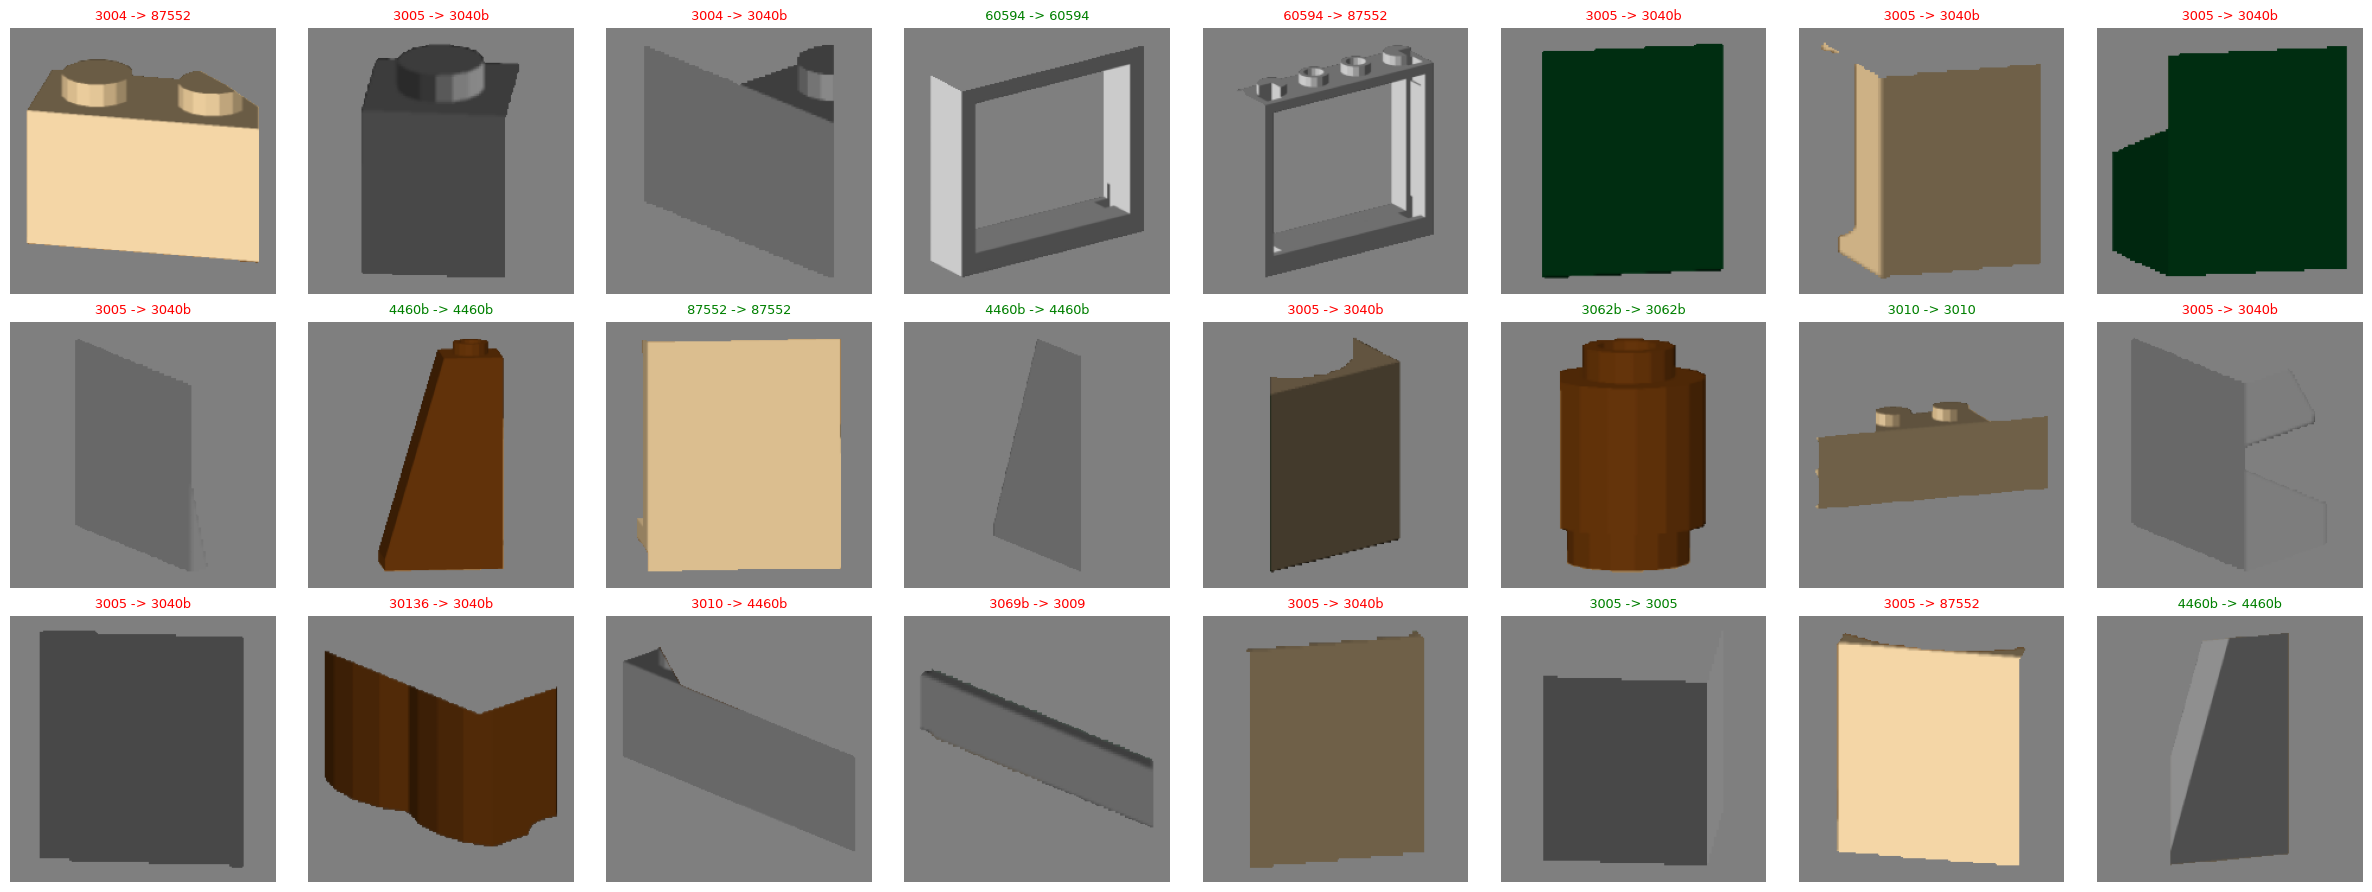

In [5]:
# SIM-TO-REAL GAP, part 2: same towers, but rendered BIG (1600 px, tower fills the frame) so bricks are not tiny. Resolution effect vs view/render effect.
# Needs the first gap cell run (emb, gal, lego_id, L, Counter).
rng2 = np.random.default_rng(5); crops, truth = [], []
for tower, _, _ in RENDERS:
    rgba, ids = R.render_scene(tower, size=1600, zoom=1.0, rng=rng2); img = np.where(rgba[..., 3:] > 0, rgba[..., :3], 127).astype(np.uint8)
    for n in np.unique(ids)[1:]:
        m = ids == n
        if m.sum() < 2500: continue   # same cut as before, scaled for the 2.3x larger picture
        ys, xs = np.where(m); bx = (xs.min(), ys.min(), xs.max(), ys.max()); mm = L.crop_box(m.astype(np.uint8) * 255, *bx) > 127
        crops.append(np.where(mm[..., None], L.crop_box(img, *bx), 127).astype(np.uint8)); truth.append((tower[n - 1]['part'], lego_id[tower[n - 1]['color']], int(m.sum())))
res = L.recognize(gal, L.embed(emb, crops), np.array([L.brick_lab(c) for c in crops]), closed_set=True, shape_min_sim=-1)
ok_s = np.array([r[0] == t[0] for r, t in zip(res, truth)]); ok_c = np.array([r[2] == t[1] for r, t in zip(res, truth)]); px = np.array([t[2] for t in truth])
print(f'{len(crops)} bricks at 1600 px | shape {ok_s.mean():.3f} | color {ok_c.mean():.3f} | both {(ok_s & ok_c).mean():.3f}   (700 px run: 0.188 / 0.635 / 0.181)')
for lo, hi in ((2500, 10000), (10000, 30000), (30000, 10 ** 9)):
    s = (px >= lo) & (px < hi); print(f'  visible area {lo}-{hi if hi < 10 ** 9 else "inf"} px: {s.sum()} bricks, shape {ok_s[s].mean() if s.any() else float("nan"):.3f}, color {ok_c[s].mean() if s.any() else float("nan"):.3f}')
print('shape mix-ups:', Counter((t[0], r[0]) for r, t, ok in zip(res, truth, ok_s) if not ok).most_common(8))
fig, ax = plt.subplots(3, 8, figsize=(24, 9))   # what the lookup actually sees: 24 crops, title = truth -> guess
for a, i in zip(ax.flat, np.random.default_rng(0).choice(len(crops), min(24, len(crops)), replace=False)):
    a.imshow(crops[i]); a.axis('off'); a.set_title(f'{truth[i][0]} -> {res[i][0]}', fontsize=9, color='green' if ok_s[i] else 'red')
plt.tight_layout(); plt.show()

**Result:** Shape barely improves (21.5%), while color improves (84%). Resolution is not the main problem. The tower view itself (side faces only, no studs) and the clean render look are.

Shut the kernel down, so GPU and RAM are freed after Run All.

In [ ]:
get_ipython().kernel.do_shutdown(False)   # last cell: kills this kernel so GPU/RAM is freed after Run All

{'status': 'ok', 'restart': False}

: 

## Conclusion
The digital tower generator works: valid stacks, exact labels, every check passed, and `.ldr` export. It is a reliable source of training data and of the output format. The gap test shows the current lookup can't name bricks seen inside a tower (shape about 20%), and that this is not a resolution problem. The gallery needs views like the ones a tower shows (wall faces, partly hidden bricks). Rendered training data like this feeds `tower_seg.ipynb`.